# Lab 2 – Outlier Detection & Feature Engineering

Student: Juan Camilo Chirivi 

ID: 9115141


## Data Source and Use Case

**Dataset:** Bank Marketing – `bank-full.csv`  
**Source:** UCI Machine Learning Repository  
**Official page:** https://archive.ics.uci.edu/dataset/222/bank+marketing  

The data comes from direct marketing campaigns of a Portuguese banking institution. The campaigns were based mainly on phone calls, and the target variable `y` indicates whether the client subscribed to a term deposit.


In [1]:
# Imports and project paths

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Find the project root whether the notebook is launched from /notebooks or from the root.
cwd = Path.cwd()

if (cwd / "data" / "bank-full.csv").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "bank-full.csv").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/bank-full.csv. "
        "Run the notebook from the project root or the notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "bank-full.csv"

# Allow imports from src/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.neon_connect import DatabaseManager

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)

Project root: d:\Conestoga\ML_Programming\Lab 2 - Tidying\cleaning-imputation-outliers
Data path: d:\Conestoga\ML_Programming\Lab 2 - Tidying\cleaning-imputation-outliers\data\bank-full.csv


## Load and Validate the Original CSV

This first local load is used to validate the file before sending it to Neon.

In [2]:
# Load the original UCI file
bank_csv = pd.read_csv(DATA_PATH, sep=";")

print("Shape:", bank_csv.shape)
print("\nColumns:")
print(bank_csv.columns.tolist())

display(bank_csv.head())

Shape: (45211, 17)

Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Basic source validation

print("Rows:", len(bank_csv))
print("Columns:", bank_csv.shape[1])
print("Duplicate rows:", bank_csv.duplicated().sum())
print("Missing values:", int(bank_csv.isna().sum().sum()))

# The project requires at least 10,000 records.
assert len(bank_csv) >= 10_000, "The dataset does not meet the 10,000-row requirement."

display(bank_csv.dtypes.to_frame("dtype"))

Rows: 45211
Columns: 17
Duplicate rows: 0
Missing values: 0


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


### Initial observation

The file contains 45,211 rows and 17 columns. The downloaded version does not contain standard `NaN` values or exact duplicate rows.

Some categorical columns contain the text `unknown`. This is not treated as a numeric outlier. For this use case, those values are kept because the main focus is numeric outlier detection and Feature Engineering.

In [4]:
# Count 'unknown' values in categorical columns without changing the dataset

categorical_columns = bank_csv.select_dtypes(include="object").columns

unknown_summary = pd.DataFrame({
    "column": categorical_columns,
    "unknown_count": [
        bank_csv[col].astype(str).str.lower().eq("unknown").sum()
        for col in categorical_columns
    ]
})

unknown_summary = unknown_summary[
    unknown_summary["unknown_count"] > 0
].reset_index(drop=True)

display(unknown_summary)

C:\Users\Admin\AppData\Local\Temp\ipykernel_30112\2731619218.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = bank_csv.select_dtypes(include="object").columns


,column,unknown_count
0,job,288
1,education,1857
2,contact,13020
3,poutcome,36959


## Upload Raw Data to Neon PostgreSQL

In [5]:
# Connect to the shared Neon database

db = DatabaseManager()

RAW_TABLE = "bank_marketing_raw"

# Set this to False after the raw table has already been uploaded
# and you only want to read it from Neon.
UPLOAD_RAW_TO_NEON = True

if UPLOAD_RAW_TO_NEON:
    db.upload_dataframe(
        bank_csv,
        table_name=RAW_TABLE,
        if_exists="replace"
    )

# From this point forward, use the database copy for the analysis.
bank = db.fetch_dataframe(
    f'SELECT * FROM "{RAW_TABLE}"'
)

print("Rows read from Neon:", len(bank))
display(bank.head())

✅ Successfully connected to Neon PostgreSQL database.
✅ Successfully uploaded 45211 rows to 'bank_marketing_raw'.
Rows read from Neon: 45211


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [6]:
# Verify that the Neon table matches the source file

print("CSV shape:", bank_csv.shape)
print("Neon shape:", bank.shape)

assert bank.shape == bank_csv.shape, "The Neon table shape does not match the source CSV."

print("Validation passed: the source CSV and Neon table have the same shape.")

CSV shape: (45211, 17)
Neon shape: (45211, 17)
Validation passed: the source CSV and Neon table have the same shape.


## Focused Exploratory Data Analysis (EDA)

The main numeric features selected are:

- `age`
- `balance`
- `duration`
- `campaign`

Other numeric fields require special interpretation. For example, `pdays` contains a special negative value and `previous` contains many zeros, so applying a generic outlier rule to them could be misleading.

The goal is not to label every unusual value as an error. The goal is to identify unusual observations and then interpret them.

In [7]:
# General dataset inspection

print("Shape:", bank.shape)
print("\nData types:")
display(bank.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(bank.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", bank.duplicated().sum())

print("\nNumeric descriptive statistics:")
display(bank.describe().T)

Shape: (45211, 17)

Data types:


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Missing values:


,missing_values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Duplicate rows: 0

Numeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [8]:
# Numeric features selected for outlier analysis

OUTLIER_FEATURES = [
    "age",
    "balance",
    "duration",
    "campaign"
]

numeric_summary = pd.DataFrame({
    "mean": bank[OUTLIER_FEATURES].mean(),
    "median": bank[OUTLIER_FEATURES].median(),
    "std": bank[OUTLIER_FEATURES].std(),
    "min": bank[OUTLIER_FEATURES].min(),
    "max": bank[OUTLIER_FEATURES].max(),
    "skewness": bank[OUTLIER_FEATURES].skew()
})

display(numeric_summary.round(2))

,mean,median,std,min,max,skewness
age,40.94,39.0,10.62,18,95,0.68
balance,1362.27,448.0,3044.77,-8019,102127,8.36
duration,258.16,180.0,257.53,0,4918,3.14
campaign,2.76,2.0,3.10,1,63,4.90


### EDA interpretation

`balance`, `duration`, and `campaign` are strongly right-skewed. Their maximum values are much larger than their medians.

This is important because:

- **Z-Score** is based on the mean and standard deviation and is more appropriate when a distribution is reasonably close to normal.
- **IQR** is based on quartiles and is more robust when data is skewed.

Because this dataset contains skewed numeric variables, it is useful to compare both methods instead of assuming that one method is always correct.

## Z-Score Outlier Detection

The Z-Score measures how many standard deviations a value is from the mean.

\[
z = \frac{x - \mu}{\sigma}
\]

Where:

- `x` = observation
- `μ` = mean
- `σ` = standard deviation

For this exercise, a value is flagged as a potential outlier when:

\[
|z| > 3
\]

This means the observation is more than three standard deviations away from the mean.

In [10]:
# Z-Score outlier detection
# The calculation is kept in the notebook so the method is visible and explainable.

Z_THRESHOLD = 3

zscore_masks = {}
zscore_rows = []

for feature in OUTLIER_FEATURES:
    mean_value = bank[feature].mean()
    std_value = bank[feature].std(ddof=0)

    # Calculate the Z-Score for every row.
    z_scores = (bank[feature] - mean_value) / std_value

    # Flag values farther than 3 standard deviations from the mean.
    outlier_mask = z_scores.abs() > Z_THRESHOLD

    zscore_masks[feature] = outlier_mask

    zscore_rows.append({
        "feature": feature,
        "mean": mean_value,
        "std": std_value,
        "z_threshold": Z_THRESHOLD,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percent": outlier_mask.mean() * 100
    })

zscore_summary = pd.DataFrame(zscore_rows)

display(zscore_summary.round(2))

,feature,mean,std,z_threshold,outlier_count,outlier_percent
0,age,40.94,10.62,3,381,0.84
1,balance,1362.27,3044.73,3,745,1.65
2,duration,258.16,257.52,3,963,2.13
3,campaign,2.76,3.10,3,840,1.86


In [11]:
# Show examples of the most extreme Z-Scores for balance

balance_mean = bank["balance"].mean()
balance_std = bank["balance"].std(ddof=0)

balance_z = (
    (bank["balance"] - balance_mean) / balance_std
)

balance_z_examples = bank[
    ["age", "job", "balance", "duration", "campaign", "y"]
].copy()

balance_z_examples["balance_zscore"] = balance_z

display(
    balance_z_examples
    .loc[balance_z.abs() > Z_THRESHOLD]
    .sort_values("balance_zscore", key=abs, ascending=False)
    .head(10)
)

,age,job,balance,duration,campaign,y,balance_zscore
39989,51,management,102127,90,1,no,33.094776
26227,59,management,98417,145,5,no,31.876278
42558,84,retired,81204,679,1,yes,26.222907
43393,84,retired,81204,390,1,yes,26.222907
41693,60,retired,71188,205,1,no,22.933291
19785,56,management,66721,442,2,no,21.466167
21192,52,blue-collar,66653,109,3,no,21.443833
19420,59,admin.,64343,45,4,no,20.685146
41374,32,entrepreneur,59649,69,2,no,19.143466
12926,56,blue-collar,58932,339,2,no,18.907978


### Z-Score interpretation

With this dataset, Z-Score identifies relatively extreme observations, but the method can be influenced by skewed distributions.

For example, a very high bank balance may be statistically unusual while still being a valid customer value. Therefore, the result is treated as a **flag for investigation**, not an automatic deletion rule.

## IQR Outlier Detection

The IQR method uses quartiles instead of the mean and standard deviation.

\[
IQR = Q3 - Q1
\]

The typical limits are:

\[
Lower = Q1 - 1.5(IQR)
\]

\[
Upper = Q3 + 1.5(IQR)
\]

Any value below the lower bound or above the upper bound is flagged as a potential outlier.

Because IQR is based on quartiles, it is usually more robust than Z-Score for skewed distributions.

In [12]:
# IQR outlier detection
# The thresholds are calculated independently for each feature.

iqr_masks = {}
iqr_bounds = {}
iqr_rows = []

for feature in OUTLIER_FEATURES:
    q1 = bank[feature].quantile(0.25)
    q3 = bank[feature].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outlier_mask = (
        (bank[feature] < lower_bound)
        | (bank[feature] > upper_bound)
    )

    iqr_masks[feature] = outlier_mask
    iqr_bounds[feature] = {
        "lower": lower_bound,
        "upper": upper_bound
    }

    iqr_rows.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percent": outlier_mask.mean() * 100
    })

iqr_summary = pd.DataFrame(iqr_rows)

display(iqr_summary.round(2))

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16
3,campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78


In [13]:
# Show some IQR outliers for balance

balance_lower = iqr_bounds["balance"]["lower"]
balance_upper = iqr_bounds["balance"]["upper"]

print("Balance lower bound:", balance_lower)
print("Balance upper bound:", balance_upper)

display(
    bank.loc[
        iqr_masks["balance"],
        ["age", "job", "balance", "duration", "campaign", "y"]
    ]
    .sort_values("balance", ascending=False)
    .head(10)
)

Balance lower bound: -1962.0
Balance upper bound: 3462.0


,age,job,balance,duration,campaign,y
39989,51,management,102127,90,1,no
26227,59,management,98417,145,5,no
43393,84,retired,81204,390,1,yes
42558,84,retired,81204,679,1,yes
41693,60,retired,71188,205,1,no
19785,56,management,66721,442,2,no
21192,52,blue-collar,66653,109,3,no
19420,59,admin.,64343,45,4,no
41374,32,entrepreneur,59649,69,2,no
12926,56,blue-collar,58932,339,2,no


## Compare Z-Score and IQR

The two methods are expected to produce different results because they use different definitions of an unusual value.

- Z-Score depends on the **mean and standard deviation**.
- IQR depends on the **middle 50% of the distribution**.
- Highly skewed data can make the methods disagree substantially.

In [14]:
# Compare outlier counts from both methods

comparison = (
    zscore_summary[
        ["feature", "outlier_count", "outlier_percent"]
    ]
    .rename(columns={
        "outlier_count": "zscore_outliers",
        "outlier_percent": "zscore_percent"
    })
    .merge(
        iqr_summary[
            ["feature", "outlier_count", "outlier_percent"]
        ].rename(columns={
            "outlier_count": "iqr_outliers",
            "outlier_percent": "iqr_percent"
        }),
        on="feature"
    )
)

display(comparison.round(2))

,feature,zscore_outliers,zscore_percent,iqr_outliers,iqr_percent
0,age,381,0.84,487,1.08
1,balance,745,1.65,4729,10.46
2,duration,963,2.13,3235,7.16
3,campaign,840,1.86,3064,6.78


### Comparison interpretation

For this `bank-full.csv` file, IQR identifies more potential outliers than Z-Score for the strongly skewed variables.

Expected counts from this dataset are approximately:

| Feature | Z-Score | IQR |
|---|---:|---:|
| age | 381 | 487 |
| balance | 745 | 4,729 |
| duration | 963 | 3,235 |
| campaign | 840 | 3,064 |

The large difference for `balance`, `duration`, and `campaign` is a good example of why the distribution shape matters. IQR is more sensitive to observations outside the central range, while Z-Score can be affected by the same extreme values that increase the mean and standard deviation.

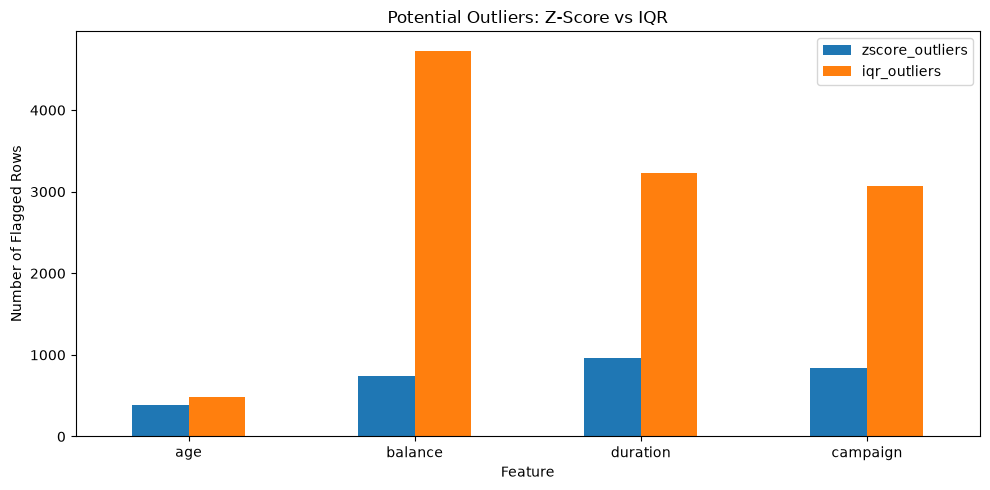

In [15]:
# Visual comparison of detected outlier counts

comparison_plot = comparison.set_index("feature")[
    ["zscore_outliers", "iqr_outliers"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Potential Outliers: Z-Score vs IQR")
plt.xlabel("Feature")
plt.ylabel("Number of Flagged Rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Outlier Treatment Decision

The detected observations are **not automatically removed**.

There is no evidence in the source file that a high bank balance, long call duration, high campaign count, or older customer is necessarily a data-entry error.

For this project:

1. The original rows are retained.
2. IQR outlier flags are added as new features.
3. Skewed variables receive transformed versions that reduce the influence of extreme values.
4. The original numeric columns are preserved for traceability.
º

## Feature Engineering

Feature Engineering help us to create new variables from existing data so the dataset can represent useful patterns more clearly.

The following features are created:

### `age_group`
Converts numeric age into understandable age categories.

### `was_previously_contacted`
Indicates whether the client had a previous campaign contact.

### `total_contacts`
Combines contacts in the current campaign and previous campaigns.

### IQR outlier flags
Creates a binary feature for each selected numeric variable.

### Transformed numeric features
Highly skewed variables receive transformed versions:

- `balance_signed_log`
- `duration_log`
- `campaign_log`

A signed logarithm is used for `balance` because balances can be negative.

In [16]:
# Create the processed dataset without overwriting the original dataframe

bank_processed = bank.copy()

# ---------------------------------------------------------
# 1. Age group
# ---------------------------------------------------------
bank_processed["age_group"] = pd.cut(
    bank_processed["age"],
    bins=[17, 29, 44, 59, np.inf],
    labels=[
        "18-29",
        "30-44",
        "45-59",
        "60+"
    ]
)

# ---------------------------------------------------------
# 2. Previous contact flag
# ---------------------------------------------------------
bank_processed["was_previously_contacted"] = (
    bank_processed["previous"] > 0
).astype(int)

# ---------------------------------------------------------
# 3. Total number of campaign contacts
# ---------------------------------------------------------
bank_processed["total_contacts"] = (
    bank_processed["campaign"]
    + bank_processed["previous"]
)

# ---------------------------------------------------------
# 4. IQR outlier flags
# ---------------------------------------------------------
for feature in OUTLIER_FEATURES:
    bank_processed[f"{feature}_iqr_outlier"] = (
        iqr_masks[feature].astype(int)
    )

# Number of selected features where the row was flagged by IQR
flag_columns = [
    f"{feature}_iqr_outlier"
    for feature in OUTLIER_FEATURES
]

bank_processed["outlier_flag_count"] = (
    bank_processed[flag_columns].sum(axis=1)
)

# ---------------------------------------------------------
# 5. Transform skewed variables
# ---------------------------------------------------------

# Signed log keeps the sign of negative balances.
bank_processed["balance_signed_log"] = (
    np.sign(bank_processed["balance"])
    * np.log1p(np.abs(bank_processed["balance"]))
)

# duration and campaign are non-negative, so log1p is enough.
bank_processed["duration_log"] = np.log1p(
    bank_processed["duration"]
)

bank_processed["campaign_log"] = np.log1p(
    bank_processed["campaign"]
)

display(bank_processed.head())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,age_group,was_previously_contacted,total_contacts,age_iqr_outlier,balance_iqr_outlier,duration_iqr_outlier,campaign_iqr_outlier,outlier_flag_count,balance_signed_log,duration_log,campaign_log
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,45-59,0,1,0,0,0,0,0,7.670429,5.568345,0.693147
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,30-44,0,1,0,0,0,0,0,3.401197,5.023881,0.693147
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,30-44,0,1,0,0,0,0,0,1.098612,4.343805,0.693147
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,45-59,0,1,0,0,0,0,0,7.317876,4.532599,0.693147
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,30-44,0,1,0,0,0,0,0,0.693147,5.293305,0.693147


### Why use log transformations?

Extreme values can make a numeric distribution very skewed.

`log1p(x)` compresses large values more than small values. This can reduce the influence of extreme observations while keeping every row.

For `balance`, a normal logarithm cannot be used directly because some balances are negative. The signed-log transformation keeps the original sign while reducing magnitude.

In [17]:
# Compare skewness before and after transformation

skew_comparison = pd.DataFrame({
    "original_skewness": [
        bank_processed["balance"].skew(),
        bank_processed["duration"].skew(),
        bank_processed["campaign"].skew()
    ],
    "transformed_skewness": [
        bank_processed["balance_signed_log"].skew(),
        bank_processed["duration_log"].skew(),
        bank_processed["campaign_log"].skew()
    ]
}, index=[
    "balance",
    "duration",
    "campaign"
])

display(skew_comparison.round(3))

,original_skewness,transformed_skewness
balance,8.360,-1.583
duration,3.144,-0.454
campaign,4.899,1.326


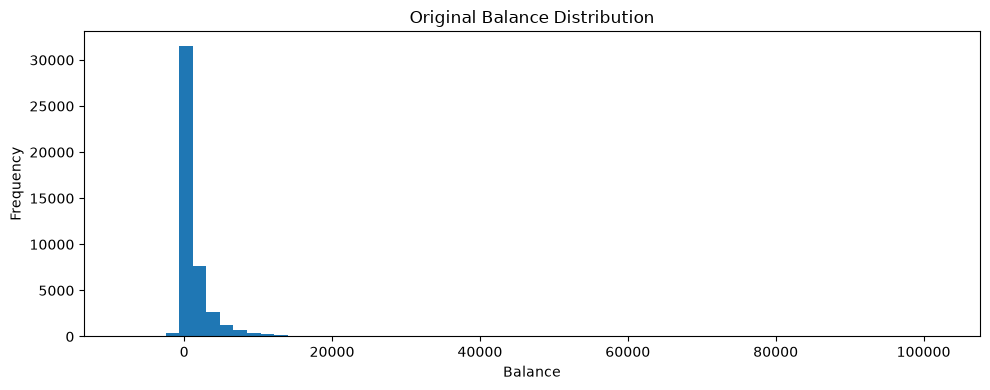

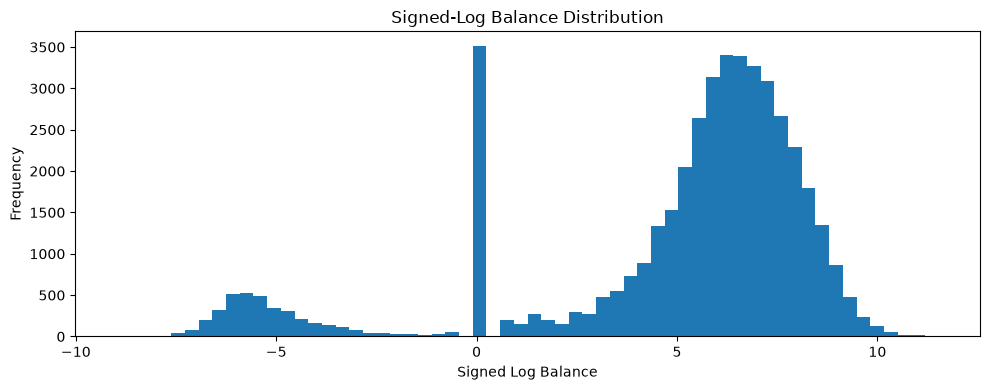

In [18]:
# Visual comparison: original balance vs transformed balance

plt.figure(figsize=(10, 4))
plt.hist(
    bank_processed["balance"],
    bins=60
)
plt.title("Original Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(
    bank_processed["balance_signed_log"],
    bins=60
)
plt.title("Signed-Log Balance Distribution")
plt.xlabel("Signed Log Balance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Validate the Processed Dataset

Validation checks that Feature Engineering did not accidentally remove rows and that the newly created columns exist as expected.

In [19]:
# Validate row preservation

print("Original rows:", len(bank))
print("Processed rows:", len(bank_processed))
print("Original columns:", bank.shape[1])
print("Processed columns:", bank_processed.shape[1])

assert len(bank_processed) == len(bank), "Feature Engineering unexpectedly changed the row count."

new_columns = [
    column
    for column in bank_processed.columns
    if column not in bank.columns
]

print("\nNew engineered features:")
for column in new_columns:
    print("-", column)

Original rows: 45211
Processed rows: 45211
Original columns: 17
Processed columns: 28

New engineered features:
- age_group
- was_previously_contacted
- total_contacts
- age_iqr_outlier
- balance_iqr_outlier
- duration_iqr_outlier
- campaign_iqr_outlier
- outlier_flag_count
- balance_signed_log
- duration_log
- campaign_log


In [20]:
# Summary of outlier flags in the processed dataset

outlier_flag_summary = pd.DataFrame({
    "feature": OUTLIER_FEATURES,
    "iqr_flagged_rows": [
        bank_processed[f"{feature}_iqr_outlier"].sum()
        for feature in OUTLIER_FEATURES
    ]
})

display(outlier_flag_summary)

,feature,iqr_flagged_rows
0,age,487
1,balance,4729
2,duration,3235
3,campaign,3064


## Upload the Processed Data to Neon

The processed data is stored in a new table instead of replacing the raw table.

This keeps the project reproducible:

- `bank_marketing_raw` = original source data
- `bank_marketing_processed` = engineered features and outlier flags

In [21]:
PROCESSED_TABLE = "bank_marketing_processed"

db.upload_dataframe(
    bank_processed,
    table_name=PROCESSED_TABLE,
    if_exists="replace"
)

# Verify the processed table directly from Neon
verification = db.fetch_dataframe(
    f'SELECT COUNT(*) AS row_count FROM "{PROCESSED_TABLE}"'
)

display(verification)

✅ Successfully uploaded 45211 rows to 'bank_marketing_processed'.


,row_count
0,45211


## Summary and Conclusions

### Outlier Detection

Both Z-Score and IQR identified potential outliers, but they did not identify the same number of observations.

IQR flagged more values in the highly skewed features `balance`, `duration`, and `campaign`. This is expected because IQR uses quartiles and is less affected by very large observations.

Z-Score is still useful because it gives a standardized measure of distance from the mean, but it should be interpreted carefully when the distribution is strongly skewed.

### Outlier Treatment

The potential outliers were **not automatically deleted**.

The extreme values can represent real customers and real campaign activity. Instead, the project:

- preserves the original rows;
- adds IQR outlier flags;
- creates transformed numeric features; and
- keeps the original numeric columns for reference.

### Feature Engineering

New features were created to make the data easier to use in later machine-learning work:

- `age_group`
- `was_previously_contacted`
- `total_contacts`
- IQR outlier indicators
- `outlier_flag_count`
- `balance_signed_log`
- `duration_log`
- `campaign_log`
